# Assignment 11C – Reinforcement Learning: Tic-Tac-Toe

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

## 1. Environment

In [9]:
WINS = [(0,1,2),(3,4,5),(6,7,8),   # rows
        (0,3,6),(1,4,7),(2,5,8),   # cols
        (0,4,8),(2,4,6)]           # diagonals

def check_winner(board):
    for a,b,c in WINS:
        if board[a] == board[b] == board[c] != 0:
            return board[a]
    return 0

def available(board):
    return [i for i, v in enumerate(board) if v == 0]

def board_key(board):
    return tuple(board)

## 2. Q-Learning Agent

In [10]:
class TicTacToeAgent:
    def __init__(self, player, alpha=0.3, gamma=0.9, epsilon=0.3):
        self.player  = player        # 1 or -1
        self.alpha   = alpha
        self.gamma   = gamma
        self.epsilon = epsilon
        self.Q       = defaultdict(float)

    def q(self, state, action):
        return self.Q[(board_key(state), action)]

    def choose_action(self, board, training=True):
        moves = available(board)
        if training and np.random.rand() < self.epsilon:
            return np.random.choice(moves)
        return max(moves, key=lambda a: self.q(board, a))

    def update(self, state, action, reward, next_state):
        moves_next  = available(next_state)
        future_val  = max([self.q(next_state, a) for a in moves_next], default=0)
        key         = (board_key(state), action)
        self.Q[key] += self.alpha * (reward + self.gamma * future_val - self.Q[key])

## 3. Training – Agent vs Agent

In [11]:
agent1 = TicTacToeAgent(player=1)
agent2 = TicTacToeAgent(player=-1)

EPISODES = 50000
results  = []      # 1=agent1 win, -1=agent2 win, 0=draw

for _ in range(EPISODES):
    board = [0] * 9

    for turn in range(9):
        agent  = agent1 if turn % 2 == 0 else agent2
        state  = board[:]
        action = agent.choose_action(board)
        board[action] = agent.player

        winner = check_winner(board)
        done   = winner != 0 or not available(board)

        if done:
            r1 = 1 if winner == 1 else (-1 if winner == -1 else 0)
            r2 = -r1 if winner != 0 else 0
            agent1.update(state, action, r1, board)
            agent2.update(state, action, r2, board)
            results.append(winner)
            break
        else:
            agent.update(state, action, 0, board)

print('Training done.')

Training done.


## 4. Training Results

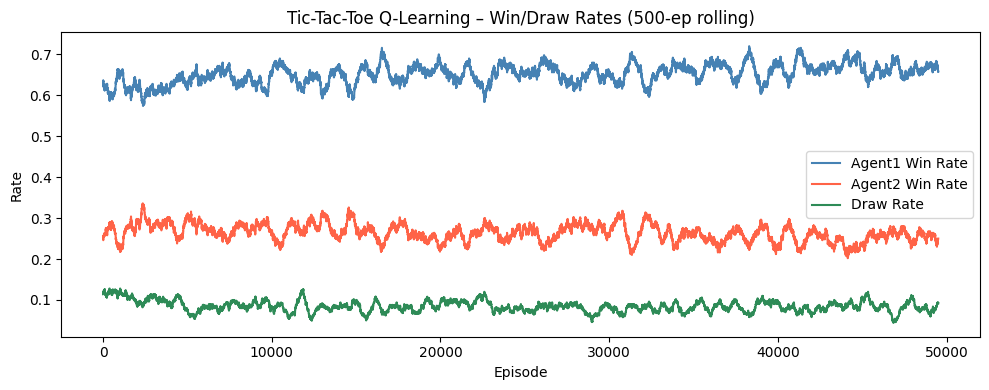

Agent1 wins: 65.1%
Agent2 wins: 26.4%
Draws      : 8.5%


In [12]:
results = np.array(results)
window  = 500
win1  = np.convolve(results ==  1, np.ones(window)/window, mode='valid')
win2  = np.convolve(results == -1, np.ones(window)/window, mode='valid')
draws = np.convolve(results ==  0, np.ones(window)/window, mode='valid')

plt.figure(figsize=(10, 4))
plt.plot(win1,  color='steelblue', label='Agent1 Win Rate')
plt.plot(win2,  color='tomato',    label='Agent2 Win Rate')
plt.plot(draws, color='seagreen',  label='Draw Rate')
plt.xlabel('Episode')
plt.ylabel('Rate')
plt.title(f'Tic-Tac-Toe Q-Learning – Win/Draw Rates ({window}-ep rolling)')
plt.legend()
plt.tight_layout()
plt.show()

total = len(results)
print(f'Agent1 wins: {(results==1).sum()/total:.1%}')
print(f'Agent2 wins: {(results==-1).sum()/total:.1%}')
print(f'Draws      : {(results==0).sum()/total:.1%}')

## 5. Test – Play a Game (Greedy)

In [13]:
def print_board(board):
    symbols = {0:'.', 1:'X', -1:'O'}
    for i in range(0, 9, 3):
        print(' '.join(symbols[v] for v in board[i:i+3]))
    print()

board = [0] * 9
for turn in range(9):
    agent  = agent1 if turn % 2 == 0 else agent2
    action = agent.choose_action(board, training=False)
    board[action] = agent.player
    print(f'Turn {turn+1} – Agent{"1" if agent.player==1 else "2"}:')
    print_board(board)
    winner = check_winner(board)
    if winner != 0 or not available(board):
        break

if winner == 1:
    print('Agent1 (X) wins!')
elif winner == -1:
    print('Agent2 (O) wins!')
else:
    print('Draw!')

Turn 1 – Agent1:
X . .
. . .
. . .

Turn 2 – Agent2:
X O .
. . .
. . .

Turn 3 – Agent1:
X O X
. . .
. . .

Turn 4 – Agent2:
X O X
O . .
. . .

Turn 5 – Agent1:
X O X
O X .
. . .

Turn 6 – Agent2:
X O X
O X O
. . .

Turn 7 – Agent1:
X O X
O X O
X . .

Agent1 (X) wins!


## 6. Outcome Distribution – Bar Chart

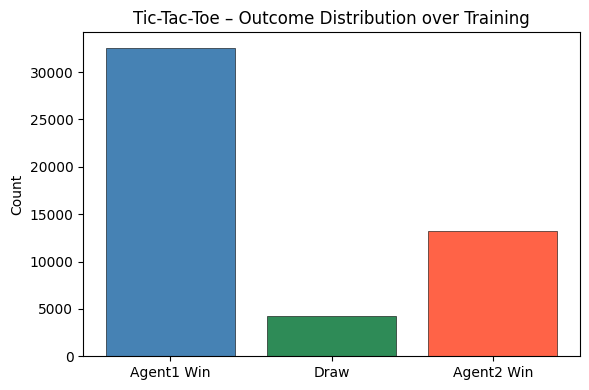

In [14]:
labels = ['Agent1 Win', 'Draw', 'Agent2 Win']
counts = [(results==1).sum(), (results==0).sum(), (results==-1).sum()]
colours = ['steelblue', 'seagreen', 'tomato']

plt.figure(figsize=(6, 4))
plt.bar(labels, counts, color=colours, edgecolor='k', linewidth=0.4)
plt.ylabel('Count')
plt.title('Tic-Tac-Toe – Outcome Distribution over Training')
plt.tight_layout()
plt.show()